# Trading book: daily hypothetical P&L

Fictional 10 M€ multi-asset book, valued every trading day from 4 January 2008 to 20 October 2026 (gold tables `fact_pnl` and `dim_position`).

Method: notionals are held constant (daily rebalancing); USD positions are converted at the ECB EUR/USD reference rate; the bond is a 10-year zero-coupon repriced from the euro area AAA 10-year spot yield (continuously compounded, as published by the ECB) at constant maturity. The P&L is hypothetical: fixed positions revalued with market moves, without trading, fees, carry or roll-down.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
GOLD = ROOT / "data" / "gold"

# Reference categorical palette (slots 1-6, validated for adjacent series); the book is drawn in ink
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
COLORS = {
    "CAC40": "#2a78d6",
    "SX5E": "#eb6834",
    "SPX": "#1baf7a",
    "GOLD": "#eda100",
    "EUR_ZC10Y": "#e87ba4",
    "USD_CASH": "#008300",
}
plt.rcParams.update(
    {
        "figure.figsize": (9, 3.6),
        "figure.dpi": 110,
        "figure.facecolor": SURFACE,
        "axes.facecolor": SURFACE,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK2,
        "axes.titlecolor": INK,
        "axes.titlesize": 11,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": GRID,
        "grid.linewidth": 0.6,
        "xtick.color": INK2,
        "ytick.color": INK2,
        "lines.linewidth": 1.5,
        "legend.frameon": False,
        "font.size": 9,
    }
)
MEUR = mtick.FuncFormatter(lambda x, _: f"{x / 1e6:g} M€")
ANNUAL = np.sqrt(252)

In [2]:
pnl = pd.read_parquet(GOLD / "fact_pnl.parquet").assign(date=lambda d: pd.to_datetime(d["date"]))
positions = pd.read_parquet(GOLD / "dim_position.parquet").set_index("position_id")
daily = pnl.pivot(index="date", columns="position_id", values="pnl_eur")[positions.index]
fx = pnl.pivot(index="date", columns="position_id", values="pnl_fx_eur")[positions.index]
book = daily.sum(axis=1)
names = positions["name"]
print(f"{len(book)} trading days, {book.index[0]:%Y-%m-%d} to {book.index[-1]:%Y-%m-%d}")
positions[["name", "notional_eur", "currency", "kind"]]

4855 trading days, 2008-01-04 to 2026-10-20


,name,notional_eur,currency,kind
position_id,,,,
CAC40,CAC 40,2000000.0,EUR,equity
SX5E,Euro Stoxx 50,2000000.0,EUR,equity
SPX,S&P 500,2000000.0,USD,equity
GOLD,Gold,1000000.0,USD,commodity
EUR_ZC10Y,10-year euro zero-coupon bond,2000000.0,EUR,bond
USD_CASH,USD cash,1000000.0,USD,cash


## 1. Cumulative P&L by position

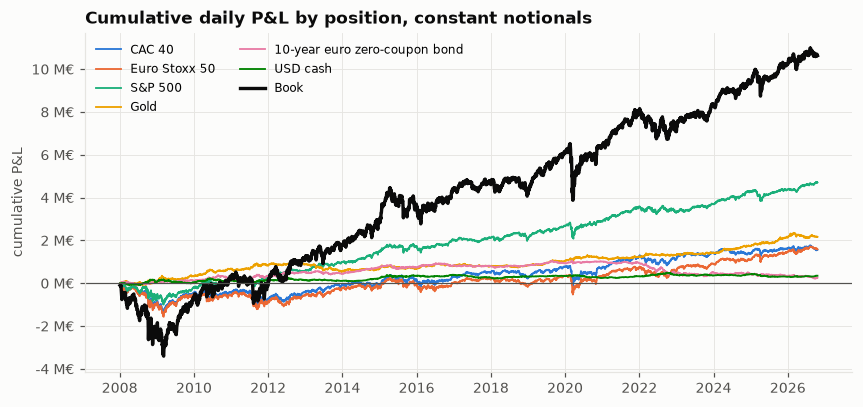

In [3]:
cumulative = daily.cumsum()
fig, ax = plt.subplots(figsize=(9, 4))
for p in positions.index:
    ax.plot(cumulative.index, cumulative[p], color=COLORS[p], linewidth=1.2, label=names[p])
ax.plot(book.index, book.cumsum(), color=INK, linewidth=2.2, label="Book")
ax.axhline(0, color=INK2, linewidth=0.8)
ax.yaxis.set_major_formatter(MEUR)
ax.set(title="Cumulative daily P&L by position, constant notionals", ylabel="cumulative P&L")
ax.legend(loc="upper left", ncols=2, fontsize=8);

Over the period the book made +10.6 M€: the S&P 500 contributed +4.7 M€ and gold +2.2 M€ on a 1 M€ notional. Part of the USD positions' gain comes from the dollar itself: EUR/USD fell from 1.4688 to 1.1234 (section 3). The bond contributed little (+0.25 M€): yields started at 4.3% and ended at 3.4%, with a fall to negative values and a sharp rise in 2022 in between.

## 2. Risk by position and diversification

In [4]:
risk = pd.DataFrame(
    {
        "notional (EUR)": positions["notional_eur"],
        "cumulative P&L (EUR)": daily.sum(),
        "annualised P&L volatility (EUR)": daily.std() * ANNUAL,
    }
)
risk.loc["BOOK"] = [positions["notional_eur"].sum(), book.sum(), book.std() * ANNUAL]
risk["volatility, % of notional"] = 100 * risk["annualised P&L volatility (EUR)"] / risk["notional (EUR)"]
diversification = 1 - book.std() / daily.std().sum()
print(
    f"Sum of the positions' volatilities: {daily.std().sum() * ANNUAL:,.0f} EUR; book: {book.std() * ANNUAL:,.0f} EUR"
)
print(f"Diversification: the book's volatility is {diversification:.1%} below the sum of its parts")
risk.rename(index={**names, "BOOK": "Book"}).round(
    {c: 1 if c.startswith("volatility, %") else 0 for c in risk}
)

Sum of the positions' volatilities: 1,674,616 EUR; book: 1,114,388 EUR
Diversification: the book's volatility is 33.5% below the sum of its parts


,notional (EUR),cumulative P&L (EUR),annualised P&L volatility (EUR),"volatility, % of notional"
position_id,,,,
CAC 40,2000000.0,1564013.0,425271.0,21.3
Euro Stoxx 50,2000000.0,1589395.0,431559.0,21.6
S&P 500,2000000.0,4706187.0,409895.0,20.5
Gold,1000000.0,2169270.0,184991.0,18.5
10-year euro zero-coupon bond,2000000.0,251460.0,134043.0,6.7
USD cash,1000000.0,350206.0,88857.0,8.9
Book,10000000.0,10630532.0,1114388.0,11.1


The book's annualised P&L volatility is 1.11 M€ (11.1% of notional), against 1.67 M€ for the sum of the stand-alone positions: diversification removes a third of the risk. Equities carry most of it (about 21% of notional each); the bond (6.7%) and USD cash (8.9%) are the low-risk positions.

**Consequence:** VaR is computed on the book P&L, never as a sum of position VaRs.

In [5]:
daily.corr().rename(index=names, columns=names).round(2)

position_id,CAC 40,Euro Stoxx 50,S&P 500,Gold,10-year euro zero-coupon bond,USD cash
position_id,,,,,,
CAC 40,1.00,0.96,0.47,-0.07,-0.21,-0.17
Euro Stoxx 50,0.96,1.00,0.48,-0.06,-0.20,-0.18
S&P 500,0.47,0.48,1.00,0.10,-0.04,0.32
Gold,-0.07,-0.06,0.10,1.00,0.17,0.27
10-year euro zero-coupon bond,-0.21,-0.20,-0.04,0.17,1.00,0.11
USD cash,-0.17,-0.18,0.32,0.27,0.11,1.00


The CAC 40 and the Euro Stoxx 50 are nearly the same risk (correlation 0.96): 4 M€ of the book sits on one factor. The bond is negatively correlated with European equities (about −0.2) and acts as a partial hedge. In euros, the S&P 500 correlates 0.47 with the CAC 40.

## 3. The dollar in the USD positions

In [6]:
rows = {}
for p in ["SPX", "GOLD", "USD_CASH"]:
    asset = daily[p] - fx[p]
    rows[names[p]] = {
        "total volatility (EUR)": daily[p].std() * ANNUAL,
        "asset part (EUR)": asset.std() * ANNUAL,
        "dollar part (EUR)": fx[p].std() * ANNUAL,
        "correlation asset vs dollar": asset.corr(fx[p]) if asset.std() > 0 else np.nan,
        "cumulative dollar P&L (EUR)": fx[p].sum(),
    }
dollar = pd.DataFrame(rows).T
dollar.round({c: 2 if c.startswith("correlation") else 0 for c in dollar})

,total volatility (EUR),asset part (EUR),dollar part (EUR),correlation asset vs dollar,cumulative dollar P&L (EUR)
S&P 500,409895.0,390885.0,177505.0,-0.12,621586.0
Gold,184991.0,182057.0,88940.0,-0.21,284282.0
USD cash,88857.0,0.0,88857.0,NaN,350206.0


For the S&P 500, the dollar adds 0.18 M€ of annualised volatility to the asset's 0.39 M€, but the two are slightly negatively correlated (−0.12): the dollar tends to strengthen when US equities fall, which cushions a euro-based holder. Over the period the dollar contributed +0.62 M€ to the S&P 500 position and +0.28 M€ to gold.

## 4. Risk changes over time

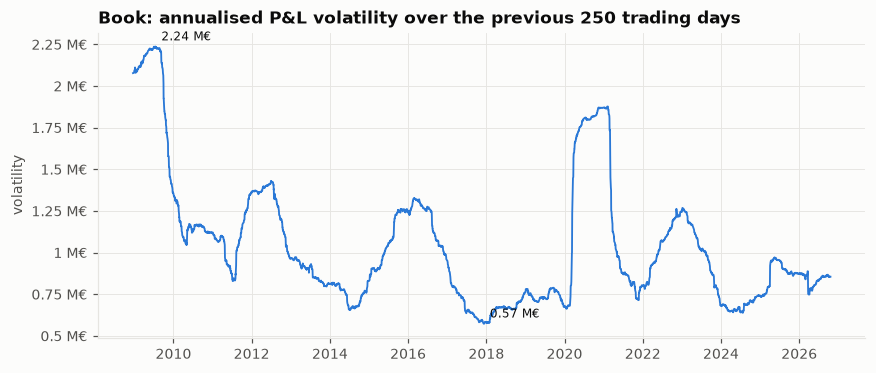

In [7]:
rolling = (book.rolling(250).std() * ANNUAL).dropna()
fig, ax = plt.subplots()
ax.plot(rolling.index, rolling, color=COLORS["CAC40"], linewidth=1.2)
for day in (rolling.idxmax(), rolling.idxmin()):
    ax.annotate(
        f"{rolling[day] / 1e6:.2f} M€",
        (day, rolling[day]),
        xytext=(4, 4),
        textcoords="offset points",
        color=INK,
        fontsize=8,
    )
ax.yaxis.set_major_formatter(MEUR)
ax.set(title="Book: annualised P&L volatility over the previous 250 trading days", ylabel="volatility");

The one-year volatility of the same book ranges from 0.57 M€ (December 2017) to 2.24 M€ (July 2009, a window covering the 2008 crisis), almost a factor of four; it is 0.86 M€ at the end of the sample.

**Consequence:** a VaR based on one long-run volatility is too low in stress and too high in calm periods; the VaR stage uses conditional volatility forecasts.

## 5. Worst days

In [8]:
worst = book.nsmallest(10).index
table = daily.loc[worst].rename(columns=names)
table["Book"] = book.loc[worst]
table["book return (%)"] = 100 * book.loc[worst] / positions["notional_eur"].sum()
print(
    f"Average daily book volatility: {book.std():,.0f} EUR; worst day: {book.min() / book.std():.1f} standard deviations"
)
table.round({c: 2 if c == "book return (%)" else 0 for c in table})

Average daily book volatility: 70,200 EUR; worst day: -9.8 standard deviations


position_id,CAC 40,Euro Stoxx 50,S&P 500,Gold,10-year euro zero-coupon bond,USD cash,Book,book return (%)
date,,,,,,,,
2020-03-12,-245535.0,-248028.0,-174768.0,-23471.0,-4023.0,8541.0,-687285.0,-6.87
2020-03-16,-115046.0,-104910.0,-248043.0,-24318.0,-20618.0,-4750.0,-517686.0,-5.18
2020-03-09,-167811.0,-168932.0,-171298.0,-8284.0,25047.0,-10475.0,-501752.0,-5.02
2008-10-15,-136392.0,-129631.0,-163742.0,8356.0,-16646.0,9321.0,-428734.0,-4.29
2008-12-01,-111718.0,-116792.0,-161399.0,-42011.0,17132.0,9438.0,-405349.0,-4.05
2020-03-18,-118714.0,-114349.0,-95337.0,-26962.0,-35566.0,4390.0,-386538.0,-3.87
2015-08-24,-106902.0,-107087.0,-114921.0,-24034.0,8632.0,-18788.0,-363100.0,-3.63
2008-10-10,-154652.0,-157601.0,-8526.0,-24019.0,-10207.0,7585.0,-347421.0,-3.47
2025-04-03,-66129.0,-71898.0,-147214.0,-40176.0,5452.0,-26494.0,-346459.0,-3.46


Four of the ten worst days fall in March 2020. The worst, 12 March 2020, cost 687 k€ (−6.87%), about ten daily standard deviations of 70 k€. On 12, 16 and 18 March the bond lost as well: euro yields rose during the March 2020 sell-off, so the equity hedge failed when it was needed. The others are the 2008 crisis, 24 August 2015 and 3 April 2025.

## Summary

| Finding | Consequence for the risk measures |
|---|---|
| Worst day ≈ 10 daily standard deviations | Heavy tails: a normal VaR understates losses |
| One-year volatility varies by almost 4× | Conditional volatility in the VaR |
| Diversification removes a third of the risk | VaR on the book P&L, not a sum of positions |
| CAC 40 and Euro Stoxx 50 correlate at 0.96 | 4 M€ concentrated on one equity factor |
| The bond hedge failed in March 2020 | Stress scenarios must not assume the hedge holds |
| Hypothetical P&L, constant maturity | No carry or roll-down in the bond P&L |